# Scalable Sequential Discrimination Algorithm Comparison

This notebook compares Greedy, Heuristic, Uniform, and Random allocation-tree strategies on the expanded 1D and 2D benchmarks. Exhaustive search is intentionally excluded because it is not practical for the larger $K$ and $M$ values.

In [69]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Find the module folder from the repository root or this folder.
working_directory = Path.cwd().resolve()
MODULE_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
if str(MODULE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(MODULE_DIRECTORY))

import approximate_comparison_analysis as comparison_analysis

# Reload local analysis code when this notebook is already open.
comparison_analysis = importlib.reload(comparison_analysis)
approximate_summary = comparison_analysis.approximate_summary
field_family_summary = comparison_analysis.field_family_summary
load_approximate_results = comparison_analysis.load_approximate_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_approximate_dataset = comparison_analysis.run_approximate_dataset

## Run settings

Test mode uses 100 deterministically sampled cases per dataset. Every field-family, $K$, and $M$ cell is represented once, and 10 seeded cells contribute one additional case. Full mode uses all 2,700 cases per dataset.

In [70]:
# Run the expanded one-dimensional and two-dimensional datasets.
DATASETS = ["benchmark_1d", "benchmark_2d"]

# False runs 100 balanced cases; True runs all 2,700 cases per dataset.
RUN_ALL_REPLICATES = False
REPLICATES_PER_CELL = None
TEST_CASES_PER_DATASET = 100
CASE_LIMIT = None if RUN_ALL_REPLICATES else TEST_CASES_PER_DATASET
CASE_SAMPLE_SEED = 20260820
RUN_SCOPE = "full" if RUN_ALL_REPLICATES else "test"
PROGRESS_EVERY = 25

# Keep scalable results separate from the compact exact comparison.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "algorithm_comparison"

print("Run mode:", "full: 2,700 cases per dataset" if RUN_ALL_REPLICATES else "test: 100 balanced cases per dataset")
print("Test-case sampling seed:", CASE_SAMPLE_SEED)
print("Results directory:", RESULTS_ROOT)

Run mode: test: 100 balanced cases per dataset
Test-case sampling seed: 20260820
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison


## Algorithm configuration

The heuristic uses beam width $B=3$. The Uniform and Random baselines use reproducible seeds. Random uses a random sensor allocation and random pair selection at each decision-tree node.

In [71]:
# Greedy has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure partial-tree beam search and allocation improvement.
HEURISTIC_PARAMETERS = {
    "beam_width": 3,
    "max_iterations": 25,
    "improvement_threshold": 1e-3,
    "initialization": "near_uniform",
    "random_seed": 0,
}

# Reproduce the near-uniform remainder placement.
UNIFORM_PARAMETERS = {"random_seed": 0}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {"random_seed": 0}

print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", HEURISTIC_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)
print("Random parameters:", RANDOM_PARAMETERS)

Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 25, 'improvement_threshold': 0.001, 'initialization': 'near_uniform', 'random_seed': 0}
Uniform parameters: {'random_seed': 0}
Random parameters: {'random_seed': 0}


## Run all four algorithms

In [72]:
# Reload the runner so an open kernel cannot reuse an older case selector.
comparison_analysis = importlib.reload(comparison_analysis)
run_approximate_dataset = comparison_analysis.run_approximate_dataset

records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_approximate_dataset(
        dataset,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
        greedy_parameters=GREEDY_PARAMETERS,
        heuristic_parameters=HEURISTIC_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
        case_limit=CASE_LIMIT,
        case_sample_seed=CASE_SAMPLE_SEED,
    )

### Running `benchmark_1d`

benchmark_1d: completed case 1/100 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/100 (gaussian, K=6, M=8)
benchmark_1d: completed case 50/100 (sinusoidal, K=5, M=6)
benchmark_1d: completed case 75/100 (quadratic, K=4, M=3)
benchmark_1d: completed case 100/100 (quadratic, K=7, M=8)


### Running `benchmark_2d`

benchmark_2d: completed case 1/100 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/100 (gaussian, K=6, M=8)
benchmark_2d: completed case 50/100 (sinusoidal, K=5, M=6)
benchmark_2d: completed case 75/100 (quadratic, K=4, M=3)
benchmark_2d: completed case 100/100 (quadratic, K=7, M=8)


## Numerical summary

In [73]:
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }

summary_lines = [
    "| Dataset | Algorithm | Cases | Budget runs | Mean error | Maximum error | Mean runtime (s) | Median runtime (s) |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    for row in approximate_summary(records):
        summary_lines.append(
            f"| {dataset} | {row['algorithm']} | {row['cases']} | {row['runs']} | "
            f"{row['mean_error']:.5f} | {row['maximum_error']:.5f} | "
            f"{row['mean_seconds']:.5f} | {row['median_seconds']:.5f} |"
        )
display(Markdown("\n".join(summary_lines)))

| Dataset | Algorithm | Cases | Budget runs | Mean error | Maximum error | Mean runtime (s) | Median runtime (s) |
|---|---|---:|---:|---:|---:|---:|---:|
| benchmark_1d | Greedy | 100 | 396 | 0.35405 | 0.77570 | 0.00402 | 0.00221 |
| benchmark_1d | Heuristic | 100 | 396 | 0.31464 | 0.74852 | 0.05556 | 0.01148 |
| benchmark_1d | Uniform | 100 | 396 | 0.54845 | 0.83044 | 0.00019 | 0.00015 |
| benchmark_1d | Random | 100 | 396 | 0.52785 | 0.83836 | 0.00018 | 0.00014 |
| benchmark_2d | Greedy | 100 | 398 | 0.39974 | 0.83513 | 0.00395 | 0.00218 |
| benchmark_2d | Heuristic | 100 | 398 | 0.34895 | 0.79709 | 0.05311 | 0.01098 |
| benchmark_2d | Uniform | 100 | 398 | 0.57702 | 0.85073 | 0.00018 | 0.00014 |
| benchmark_2d | Random | 100 | 398 | 0.55748 | 0.85510 | 0.00017 | 0.00014 |

## Overall error-curve summary

Each row matches one point in the overall mean-error curves. The final column reports the error reduction achieved by the Heuristic relative to Greedy; positive values mean the Heuristic is better.

In [74]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}$ | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['error_reduction']:.4f} "
            f"({row['error_reduction_percent']:.1f}%) |"
        )
display(Markdown("\n".join(curve_summary_lines)))

| Dimension | Budget level | Mean $N/N_{\min}$ | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Heuristic reduction from Greedy |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.159 | 0.5534 | 0.5060 | 0.6737 | 0.6723 | 0.0474 (8.6%) |
| 1D | 2 | 0.302 | 0.3837 | 0.3439 | 0.5941 | 0.5626 | 0.0397 (10.4%) |
| 1D | 3 | 0.453 | 0.2709 | 0.2217 | 0.4973 | 0.4756 | 0.0492 (18.2%) |
| 1D | 4 | 0.570 | 0.2021 | 0.1816 | 0.4236 | 0.3956 | 0.0206 (10.2%) |
| 2D | 1 | 0.148 | 0.5800 | 0.5427 | 0.6810 | 0.6854 | 0.0373 (6.4%) |
| 2D | 2 | 0.285 | 0.4306 | 0.3647 | 0.6134 | 0.5895 | 0.0659 (15.3%) |
| 2D | 3 | 0.428 | 0.3283 | 0.2690 | 0.5394 | 0.5088 | 0.0593 (18.1%) |
| 2D | 4 | 0.544 | 0.2572 | 0.2167 | 0.4722 | 0.4440 | 0.0405 (15.7%) |

## Runtime summary by number of fields

Runtime cells report the median execution time over all included sensor budgets, locations, field families, and replicates for each $K$. The final column is the paired Heuristic-to-Greedy runtime ratio; values above 1 mean the Heuristic takes longer.

In [75]:
runtime_summary_lines = [
    "| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['greedy_median_seconds']:.6f} | "
            f"{row['heuristic_median_seconds']:.6f} | "
            f"{row['uniform_median_seconds']:.6f} | "
            f"{row['random_median_seconds']:.6f} | "
            f"{row['heuristic_to_greedy_ratio']:.2f}x |"
        )
display(Markdown("\n".join(runtime_summary_lines)))

| Dimension | $K$ | Greedy median runtime (s) | Heuristic median runtime (s) | Uniform median runtime (s) | Random median runtime (s) | Heuristic / Greedy runtime |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 0.000318 | 0.000527 | 0.000043 | 0.000043 | 1.83x |
| 1D | 4 | 0.001002 | 0.002515 | 0.000083 | 0.000081 | 2.69x |
| 1D | 5 | 0.002198 | 0.010683 | 0.000148 | 0.000141 | 4.72x |
| 1D | 6 | 0.004273 | 0.041403 | 0.000234 | 0.000228 | 9.50x |
| 1D | 7 | 0.008410 | 0.178776 | 0.000392 | 0.000378 | 19.13x |
| 2D | 3 | 0.000367 | 0.000537 | 0.000043 | 0.000042 | 1.71x |
| 2D | 4 | 0.000933 | 0.002446 | 0.000079 | 0.000076 | 2.72x |
| 2D | 5 | 0.002207 | 0.010681 | 0.000140 | 0.000138 | 4.91x |
| 2D | 6 | 0.004294 | 0.042177 | 0.000225 | 0.000218 | 9.11x |
| 2D | 7 | 0.008697 | 0.160365 | 0.000381 | 0.000376 | 18.41x |

## Error summary by field family

Each row averages final error over all included $K$, $M$, sensor budgets, and replicates. The final column reports the Heuristic error reduction relative to Greedy.

In [76]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Heuristic reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['heuristic_reduction']:.4f} "
            f"({row['heuristic_reduction_percent']:.1f}%) |"
        )
display(Markdown("\n".join(family_summary_lines)))

| Dimension | Field family | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Heuristic reduction from Greedy |
|---|---|---:|---:|---:|---:|---:|
| 1D | gaussian | 0.3836 | 0.3497 | 0.5828 | 0.5650 | 0.0339 (8.8%) |
| 1D | sinusoidal | 0.2388 | 0.2070 | 0.4372 | 0.4234 | 0.0318 (13.3%) |
| 1D | quadratic | 0.4338 | 0.3819 | 0.6198 | 0.5900 | 0.0519 (12.0%) |
| 2D | gaussian | 0.4963 | 0.4423 | 0.6544 | 0.6367 | 0.0540 (10.9%) |
| 2D | sinusoidal | 0.2443 | 0.2058 | 0.4384 | 0.4311 | 0.0384 (15.7%) |
| 2D | quadratic | 0.4546 | 0.3951 | 0.6344 | 0.6014 | 0.0595 (13.1%) |

## Comparison plots

The detailed mean-error figure retains separate panels for each $K$. A second summarized figure shows only 1D and 2D panels, averaged across all included $K$, $M$, and field families. Both use solid lines without confidence intervals. The field-family figure uses vertical boxplots and the same algorithm colors. The heuristic-iteration figure shows the distribution of iterations performed before stopping, with the configured maximum shown by a dashed line.

### Mean error curves

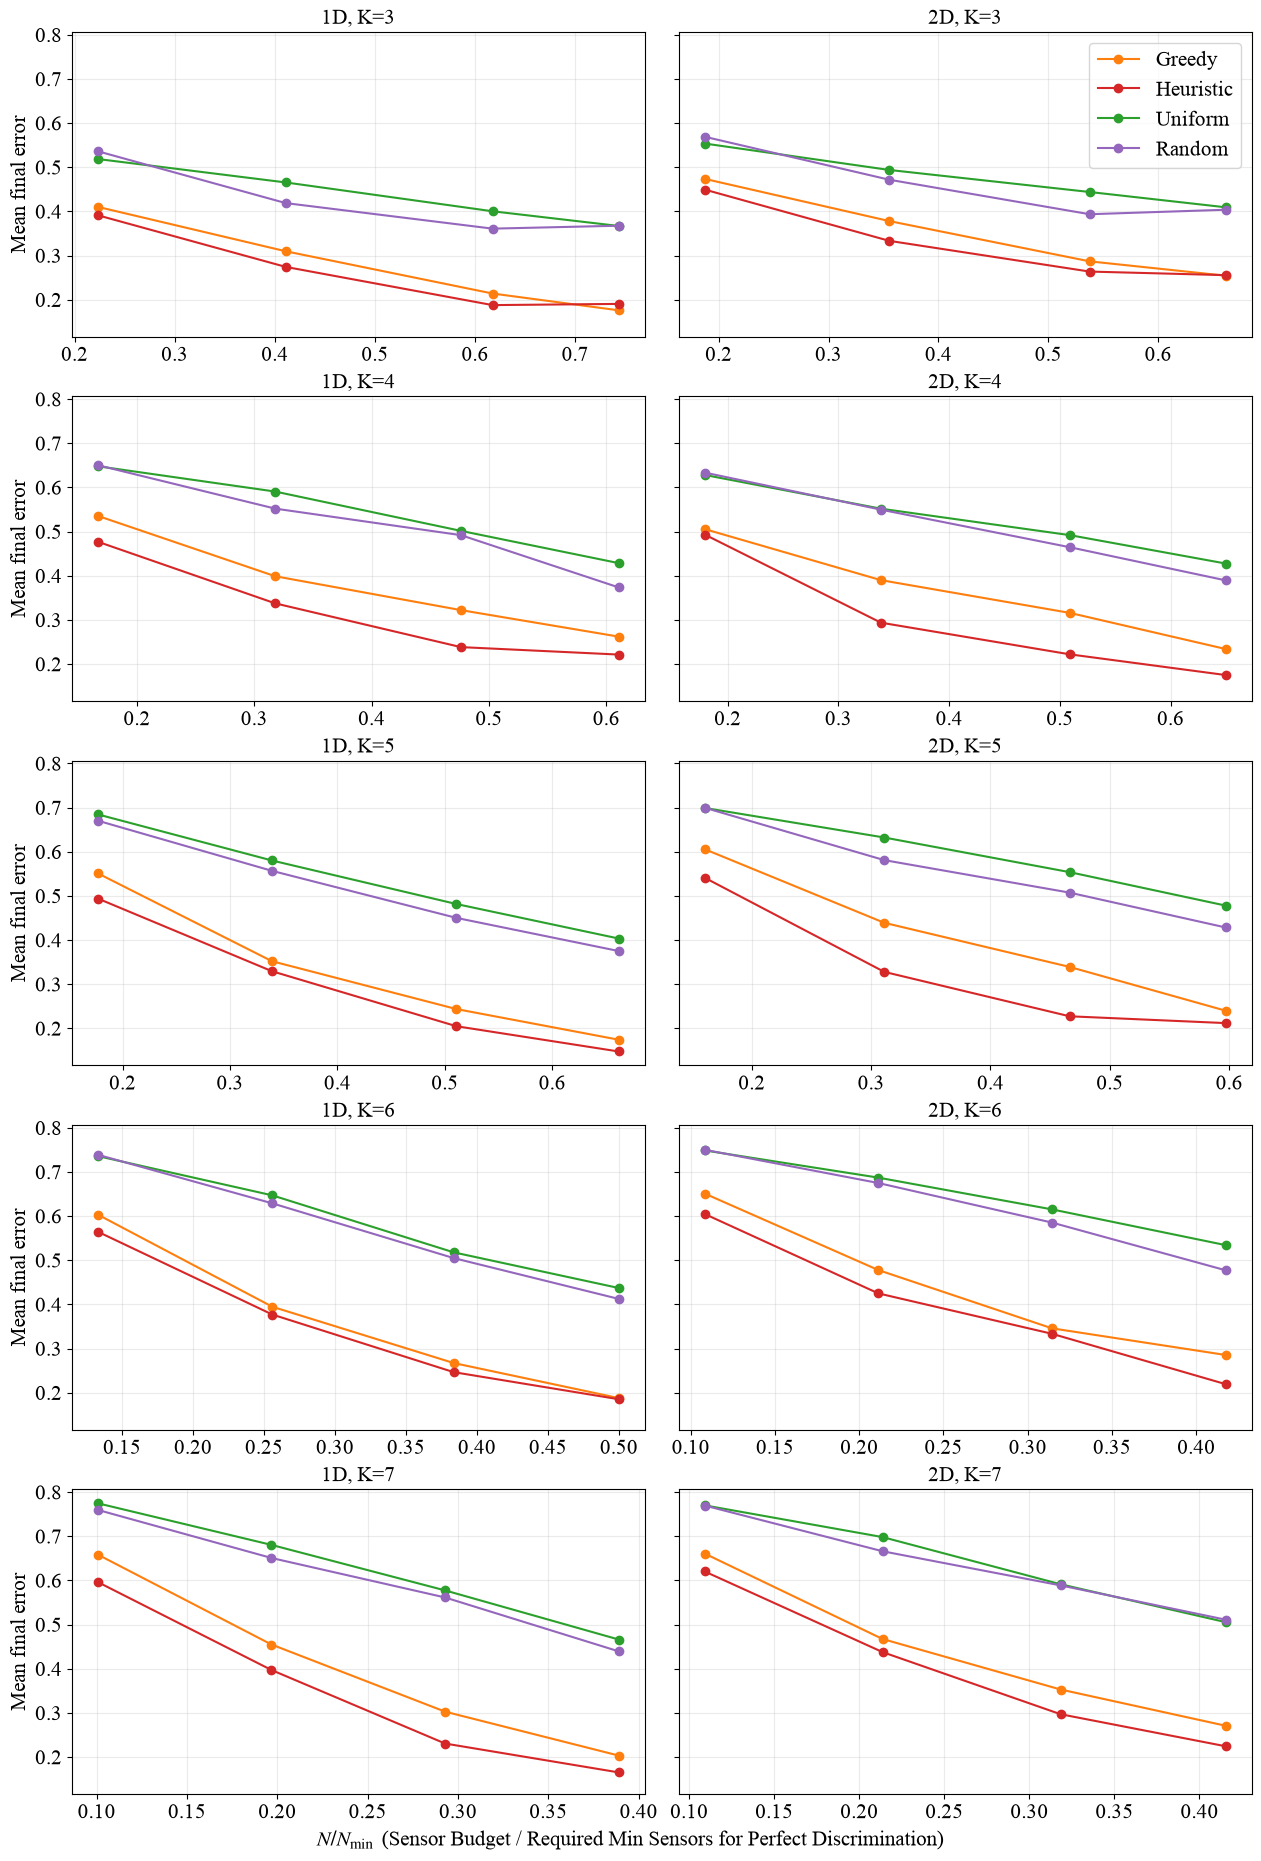

### Overall mean error curves

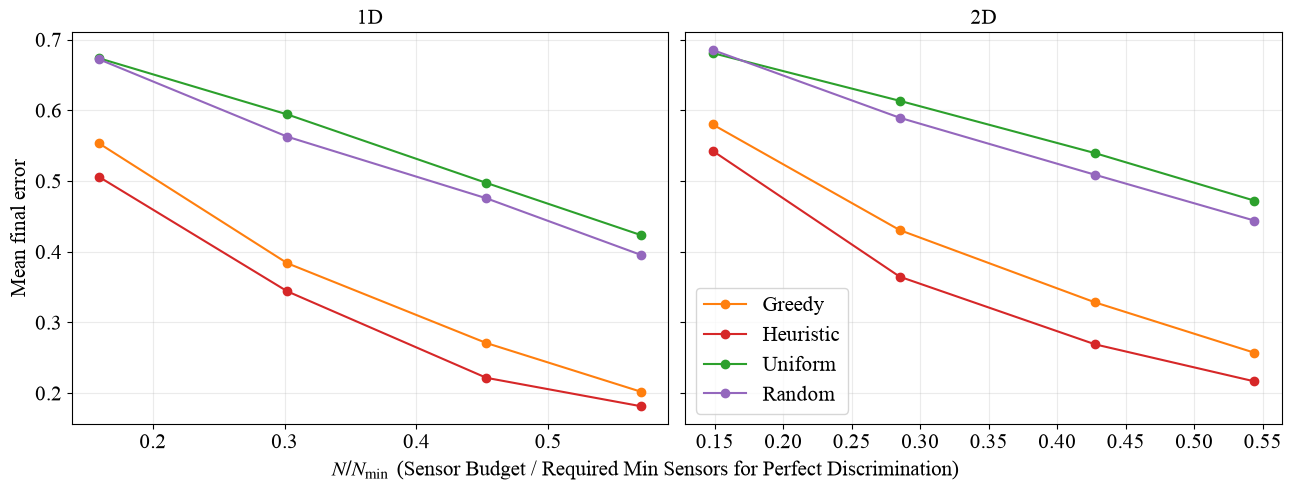

### Error distribution by field family

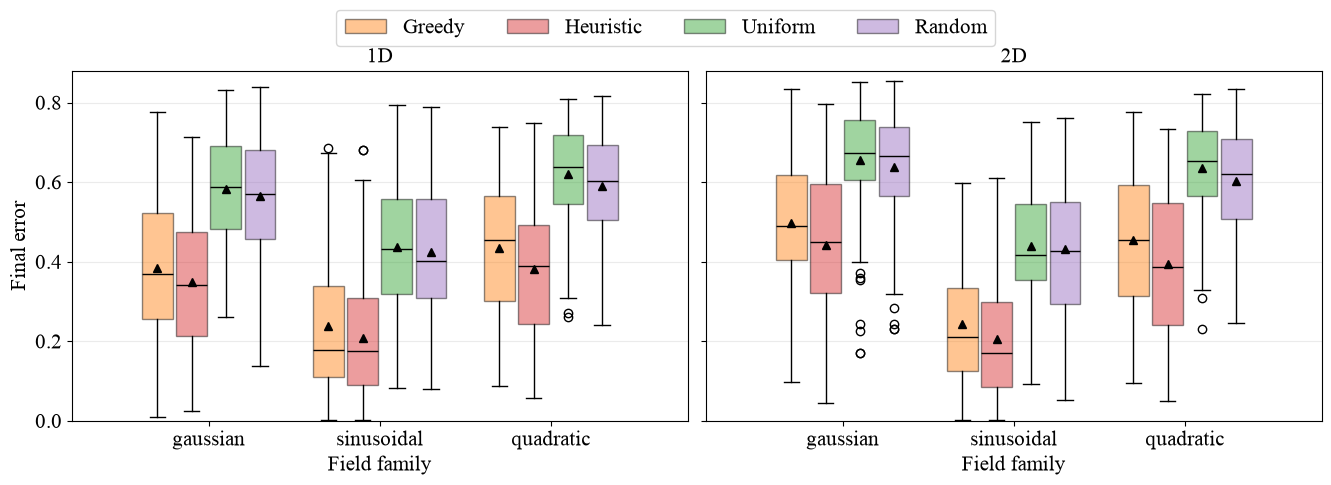

### Heuristic iteration distribution

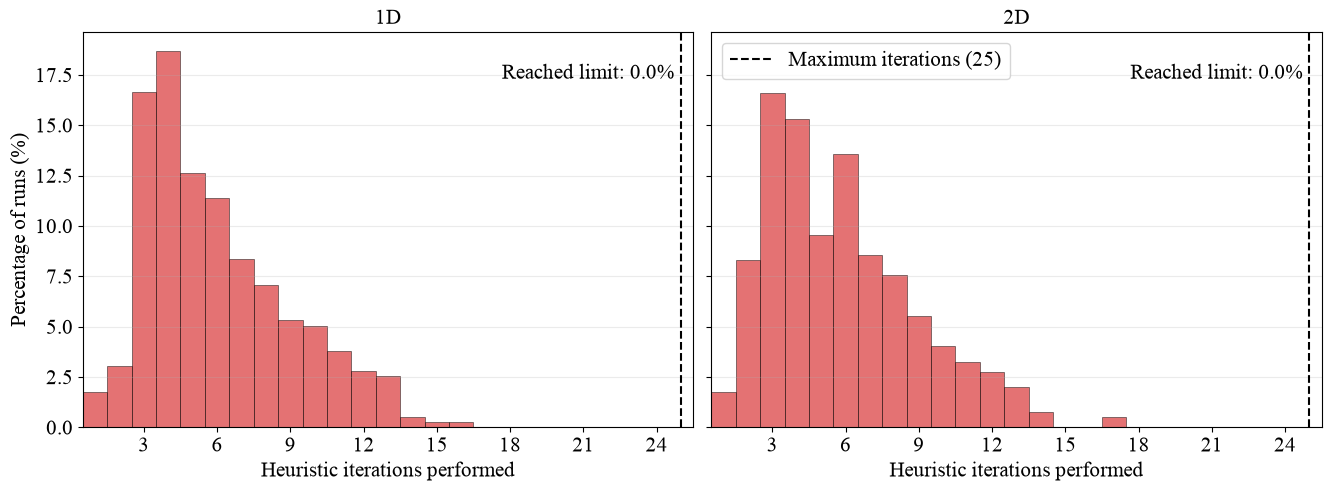

In [77]:
# Close figures left in memory by an earlier notebook run.
plt.close("all")

# Reload and apply the shared style before creating new figures.
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse an older function.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_approximate_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
figures = comparison_analysis.make_combined_approximate_plots(
    records_by_dataset,
    results_root=RESULTS_ROOT,
    run_scope=RUN_SCOPE,
)
for title, figure in figures:
    display(Markdown(f"### {title}"))
    display(figure)
    plt.close(figure)

## Saved files

```text
results/algorithm_comparison/
├── benchmark_1d_results_<test|full>/tables/
├── benchmark_2d_results_<test|full>/tables/
└── results_summary_benchmark_1d_benchmark_2d_<test|full>/figures/
```